# Временные ряды. Домашнее задание 1
## Прогноз среднемесячной температуры: Беларусь

**Датасет:** [Climate Change: Earth Surface Temperature Data](https://www.kaggle.com/datasets/berkeleyearth/climate-change-earth-surface-temperature-data) (Berkeley Earth), файл `GlobalLandTemperaturesByCountry.csv`.
**Страна:** Belarus. **Целевая переменная:** `AverageTemperature`, °C.

| № | Раздел | Что сделано |
|---|---|---|
| 1 | Подготовка данных | загрузка, фильтрация по стране, индекс-дата, проверка пропусков и частоты, графики ряда |
| 2 | Holdout-разбиение | 80% train / 20% test строго по времени + график |
| 3 | Rolling window | окно обучения 120 мес., горизонт 12 мес., проверки и визуализация сплитов |
| 4 | Генерация признаков | `lag_1`, `lag_12`, `month`, `is_winter` |
| 5 | Моделирование | линейная регрессия, прогноз на holdout-тесте, проверка на утечки |
| 6 | Метрики | MAE, RMSE, MAPE, сравнение с бейзлайнами, интерпретация |
| 7 | Дополнительно | backtesting модели на скользящем окне |

*Запуск:* положите `GlobalLandTemperaturesByCountry.csv` в папку `data/` рядом с ноутбуком (или сам zip-архив с Kaggle) и выполните `Run All`. Нужны `pandas`, `numpy`, `matplotlib`, `scikit-learn`.

In [1]:
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from IPython.display import display

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 20)

# Единые цвета: одна и та же сущность везде одного цвета
COLOR_TRAIN = '#2a78d6'   # обучающая часть
COLOR_TEST = '#eb6834'    # тестовая часть (факт)
COLOR_PRED = '#1baf7a'    # прогноз базовой линейной регрессии
COLOR_PRED2 = '#6250d6'   # прогноз улучшенной линейной регрессии (sin/cos месяца)
COLOR_INK = '#0b0b0b'
COLOR_MUTED = '#52514e'
COLOR_SURFACE = '#fcfcfb'

plt.rcParams.update({
    'figure.figsize': (13, 4.5),
    'figure.dpi': 100,
    'figure.facecolor': COLOR_SURFACE,
    'axes.facecolor': COLOR_SURFACE,
    'axes.edgecolor': '#c3c2b7',
    'axes.labelcolor': COLOR_MUTED,
    'axes.titlesize': 13,
    'axes.titleweight': 'semibold',
    'axes.titlecolor': COLOR_INK,
    'axes.titlelocation': 'left',
    'axes.titlepad': 28,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'axes.axisbelow': True,
    'grid.color': '#e6e5e0',
    'grid.linewidth': 0.8,
    'xtick.color': COLOR_MUTED,
    'ytick.color': COLOR_MUTED,
    'legend.frameon': False,
    'lines.linewidth': 1.2,
})

MONTH_NAMES = ['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн', 'Июл', 'Авг', 'Сен', 'Окт', 'Ноя', 'Дек']


def legend_above(ax, ncol=3, **kwargs):
    # Легенда между заголовком и областью графика, чтобы не перекрывать данные
    ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncol=ncol, borderaxespad=0.2, **kwargs)

## 1. Подготовка данных
### 1.1 Загрузка датасета и фильтрация по стране

In [2]:
DATA_FILE = 'GlobalLandTemperaturesByCountry.csv'
COUNTRY = 'Belarus'


def load_dataset(file_name=DATA_FILE):
    # Ищем CSV в data/ или рядом с ноутбуком; если есть только zip-архив с Kaggle - читаем CSV прямо из него
    for path in [Path('data') / file_name, Path(file_name)]:
        if path.exists():
            return pd.read_csv(path)
    for zip_path in sorted(Path('.').glob('*.zip')) + sorted(Path('data').glob('*.zip')):
        with zipfile.ZipFile(zip_path) as zf:
            if file_name in zf.namelist():
                with zf.open(file_name) as f:
                    return pd.read_csv(f)
    raise FileNotFoundError(f'Не найден {file_name}: положите его в папку data/ рядом с ноутбуком')


raw = load_dataset()
print('Размер всего датасета:', raw.shape)
print('Число стран:', raw['Country'].nunique())
raw.head()

Размер всего датасета: (577462, 4)
Число стран: 243


,dt,AverageTemperature,AverageTemperatureUncertainty,Country
0,1743-11-01,4.384,2.294,Åland
1,1743-12-01,NaN,NaN,Åland
2,1744-01-01,NaN,NaN,Åland
3,1744-02-01,NaN,NaN,Åland
4,1744-03-01,NaN,NaN,Åland


In [3]:
assert COUNTRY in set(raw['Country']), f'Страны {COUNTRY} нет в датасете'
df = raw.loc[raw['Country'] == COUNTRY].copy()
print(f'{COUNTRY}: {len(df)} строк')
df.head()

Belarus: 3239 строк


,dt,AverageTemperature,AverageTemperatureUncertainty,Country
54721,1743-11-01,0.767,2.465,Belarus
54722,1743-12-01,NaN,NaN,Belarus
54723,1744-01-01,NaN,NaN,Belarus
54724,1744-02-01,NaN,NaN,Belarus
54725,1744-03-01,NaN,NaN,Belarus


### 1.2 Индекс-дата, проверка пропусков и частоты

In [4]:
df['dt'] = pd.to_datetime(df['dt'], format='%Y-%m-%d')
df = df.set_index('dt').sort_index()
df.index.name = 'date'

print('Тип индекса:', type(df.index).__name__)
print('Период:', df.index.min().date(), '—', df.index.max().date())
print('Дубликаты дат:', df.index.duplicated().sum())

# Частота: все ли месяцы календаря присутствуют в индексе?
full_range = pd.date_range(df.index.min(), df.index.max(), freq='MS')
print('Частота по pd.infer_freq:', pd.infer_freq(df.index), '(MS = начало месяца)')
print('Месяцев в календаре:', len(full_range), '| строк в данных:', len(df),
      '| отсутствующих дат:', len(full_range.difference(df.index)))

# Пропуски в самих значениях
print('\nПропуски по столбцам:')
print(df.isna().sum())

Тип индекса: DatetimeIndex
Период: 1743-11-01 — 2013-09-01
Дубликаты дат: 0
Частота по pd.infer_freq: MS (MS = начало месяца)
Месяцев в календаре: 3239 | строк в данных: 3239 | отсутствующих дат: 0

Пропуски по столбцам:
AverageTemperature               73
AverageTemperatureUncertainty    73
Country                           0
dtype: int64


In [5]:
# Где именно пропуски в температуре: число NaN-месяцев по годам
na_by_year = df.loc[df['AverageTemperature'].isna()].index.year.value_counts().sort_index()
na_by_year.rename('NaN-месяцев').to_frame().T

date,1743,1744,1745,1746,1747,1748,1749,1750,1751,1752,2013
NaN-месяцев,1,4,8,12,12,12,12,1,4,6,1


In [6]:
# Насколько надёжны измерения в разные эпохи: средняя неопределённость (°C) по 50-летиям
unc = df['AverageTemperatureUncertainty']
unc.groupby((unc.index.year // 50) * 50).mean().round(2).rename('Средняя неопределённость, °C').to_frame().T

date,1700,1750,1800,1850,1900,1950,2000
"Средняя неопределённость, °C",2.37,4.11,2.54,0.93,0.45,0.26,0.23


**Вывод.** Дат-пропусков нет (частота строго месячная, `MS`), но есть 73 NaN в температуре: 72 из них в 1743–1752 гг. (ранние разрозненные наблюдения) и один в последнем месяце 2013-09. Неопределённость измерений в XVIII — первой половине XIX в. составляет 2.4–4.1 °C, во второй половине XIX в. ≈ 0.9 °C, а с 1900 г. опускается ниже 0.5 °C, поэтому для моделирования берём непрерывный и надёжный отрезок **1900-01 — 2013-08**. Заполнять пропуски не нужно: в этом отрезке их нет (проверяем ниже).

In [7]:
START, END = '1900-01-01', '2013-08-01'
ts = df.loc[START:END, 'AverageTemperature'].asfreq('MS')   # явно фиксируем месячную частоту
ts.name = 'temp'

assert ts.isna().sum() == 0, 'в выбранном периоде остались пропуски'
assert ts.index.is_monotonic_increasing and ts.index.is_unique
print('Тип индекса:', type(ts.index).__name__, '| частота:', ts.index.freqstr)
print('Период:', f'{ts.index.min():%Y-%m} — {ts.index.max():%Y-%m}', '| наблюдений:', len(ts), '| пропусков:', ts.isna().sum())
ts.describe().round(2).to_frame().T

Тип индекса: DatetimeIndex | частота: MS
Период: 1900-01 — 2013-08 | наблюдений: 1364 | пропусков: 0


,count,mean,std,min,25%,50%,75%,max
temp,1364.0,6.16,9.03,-16.53,-1.69,6.41,14.84,22.81


### 1.3 Базовый график временного ряда

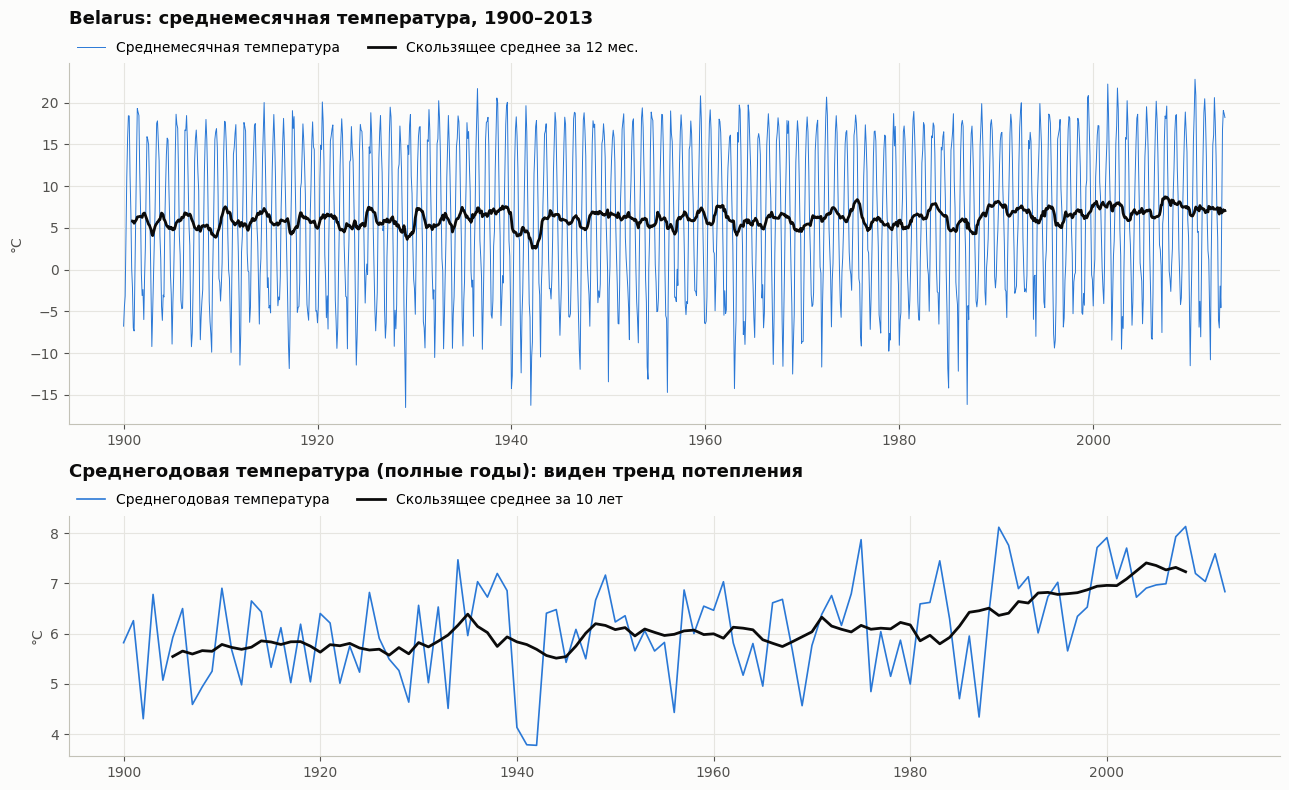

In [8]:
annual = ts.resample('YS').agg(['mean', 'count'])
annual = annual.loc[annual['count'] == 12, 'mean']           # только полные годы (2013 неполный)

fig, axes = plt.subplots(2, 1, figsize=(13, 8), gridspec_kw={'height_ratios': [3, 2]})

ax = axes[0]
ax.plot(ts.index, ts, color=COLOR_TRAIN, lw=0.7, label='Среднемесячная температура')
ax.plot(ts.index, ts.rolling(12).mean(), color=COLOR_INK, lw=2, label='Скользящее среднее за 12 мес.')
ax.set_title(f'{COUNTRY}: среднемесячная температура, {ts.index.year.min()}–{ts.index.year.max()}')
ax.set_ylabel('°C')
legend_above(ax, ncol=2)

ax = axes[1]
ax.plot(annual.index, annual, color=COLOR_TRAIN, lw=1.2, label='Среднегодовая температура')
ax.plot(annual.index, annual.rolling(10, center=True).mean(), color=COLOR_INK, lw=2,
        label='Скользящее среднее за 10 лет')
ax.set_title('Среднегодовая температура (полные годы): виден тренд потепления')
ax.set_ylabel('°C')
legend_above(ax, ncol=2)

fig.tight_layout()
plt.show()

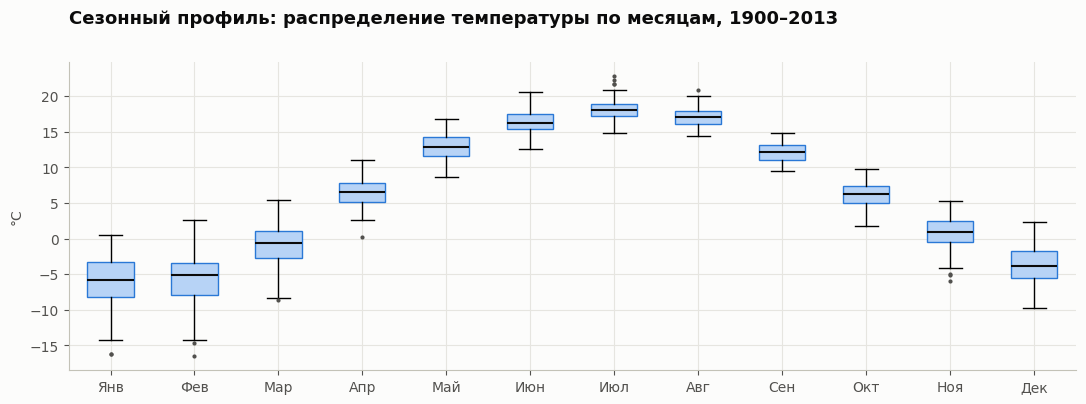

Стандартное отклонение, °C: зима (дек–фев) = 3.28 | лето (июн–авг) = 1.46


In [9]:
fig, ax = plt.subplots(figsize=(13, 4))
by_month = [ts[ts.index.month == m].values for m in range(1, 13)]
bp = ax.boxplot(by_month, patch_artist=True, widths=0.55,
                medianprops={'color': COLOR_INK, 'lw': 1.5},
                flierprops={'marker': 'o', 'markersize': 3, 'markerfacecolor': COLOR_MUTED, 'markeredgecolor': 'none'})
for box in bp['boxes']:
    box.set(facecolor='#b7d3f6', edgecolor=COLOR_TRAIN)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(MONTH_NAMES)
ax.set_title('Сезонный профиль: распределение температуры по месяцам, 1900–2013')
ax.set_ylabel('°C')
plt.show()

std_by_month = ts.groupby(ts.index.month).std()
print('Стандартное отклонение, °C: зима (дек–фев) =', round(std_by_month[[12, 1, 2]].mean(), 2),
      '| лето (июн–авг) =', round(std_by_month[[6, 7, 8]].mean(), 2))

**Комментарий.** Ряд имеет ярко выраженную годовую сезонность (от ≈ −6 °C в январе до ≈ +18 °C в июле) и слабый тренд потепления: среднегодовая температура с конца 1980-х устойчиво выше, чем в начале XX века. Зимой температура намного изменчивее, чем летом, поэтому индикатор зимы — осмысленный признак, а наибольшие ошибки прогноза ожидаются именно зимой.

## 2. Holdout-разбиение: 80% train / 20% test
Временной ряд нельзя перемешивать: обучаемся на первых 80% наблюдений, тестируемся на последних 20%, чтобы модель не видела будущего.

In [10]:
TRAIN_SHARE = 0.8
split_idx = int(len(ts) * TRAIN_SHARE)
train, test = ts.iloc[:split_idx], ts.iloc[split_idx:]

assert len(train) + len(test) == len(ts)
assert train.index.max() < test.index.min()          # разбиение по времени, без пересечения

print(f'Train: {train.index.min():%Y-%m} — {train.index.max():%Y-%m}  ({len(train)} мес., {len(train) / len(ts):.1%})')
print(f'Test:  {test.index.min():%Y-%m} — {test.index.max():%Y-%m}  ({len(test)} мес., {len(test) / len(ts):.1%})')

Train: 1900-01 — 1990-11  (1091 мес., 80.0%)
Test:  1990-12 — 2013-08  (273 мес., 20.0%)


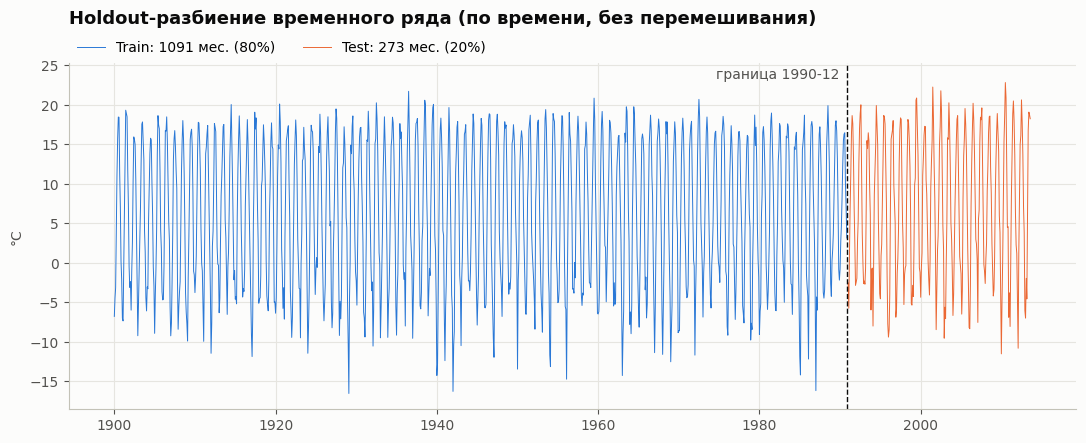

In [11]:
fig, ax = plt.subplots()
ax.plot(train.index, train, color=COLOR_TRAIN, lw=0.7, label=f'Train: {len(train)} мес. (80%)')
ax.plot(test.index, test, color=COLOR_TEST, lw=0.7, label=f'Test: {len(test)} мес. (20%)')
ax.axvline(test.index[0], color=COLOR_INK, ls='--', lw=1)
ax.annotate(f'граница {test.index[0]:%Y-%m}', xy=(test.index[0], ts.max() + 1), xytext=(-6, 0),
            textcoords='offset points', ha='right', va='center', color=COLOR_MUTED)
ax.set_ylim(ts.min() - 2, ts.max() + 2.5)
ax.set_title('Holdout-разбиение временного ряда (по времени, без перемешивания)')
ax.set_ylabel('°C')
legend_above(ax, ncol=2)
plt.show()

**Комментарий.** Тест — последние ≈ 23 года (1990-12 — 2013-08), то есть самый тёплый период ряда; модель проверяется на будущем относительно обучения, как и при реальном прогнозировании.

## 3. Скользящее окно (rolling window)
Окно обучения фиксированной длины **120 мес. (10 лет)** сдвигается по ряду с шагом 12 мес., следующие **12 мес.** после окна — горизонт прогноза. В отличие от расширяющегося окна (expanding), старая история «забывается», и на каждом сплите модель видит одинаковый объём данных.

In [12]:
def rolling_window_split(n_samples, train_size=120, horizon=12, step=None):
    # Генератор позиционных индексов (train_idx, test_idx) для rolling-window backtesting.
    # train_idx - окно фиксированной длины train_size;
    # test_idx  - следующие horizon наблюдений сразу после окна;
    # step      - сдвиг окна (по умолчанию = horizon, тестовые отрезки не пересекаются).
    step = horizon if step is None else step
    start = 0
    while start + train_size + horizon <= n_samples:
        train_idx = np.arange(start, start + train_size)
        test_idx = np.arange(start + train_size, start + train_size + horizon)
        yield train_idx, test_idx
        start += step


TRAIN_WINDOW, HORIZON = 120, 12
splits = list(rolling_window_split(len(ts), train_size=TRAIN_WINDOW, horizon=HORIZON))

# Проверки корректности разбиения
for tr_idx, te_idx in splits:
    assert len(tr_idx) == TRAIN_WINDOW and len(te_idx) == HORIZON
    assert tr_idx[-1] + 1 == te_idx[0]                        # тест сразу после окна: без зазора и пересечения
assert all(nxt[0][0] - cur[0][0] == HORIZON for cur, nxt in zip(splits, splits[1:]))   # шаг окна = 12 мес.

print('Число сплитов на ряду 1900–2013:', len(splits))
print('Наблюдений, не попавших ни в один тест (хвост ряда):', len(ts) - (splits[-1][1][-1] + 1))


def describe_split(k, tr_idx, te_idx, index):
    return {'split': k,
            'train_start': f'{index[tr_idx[0]]:%Y-%m}', 'train_end': f'{index[tr_idx[-1]]:%Y-%m}',
            'test_start': f'{index[te_idx[0]]:%Y-%m}', 'test_end': f'{index[te_idx[-1]]:%Y-%m}',
            'n_train': len(tr_idx), 'n_test': len(te_idx)}


pd.DataFrame([describe_split(k, tr, te, ts.index) for k, (tr, te) in enumerate(splits[:5], 1)]).set_index('split')

Число сплитов на ряду 1900–2013: 103
Наблюдений, не попавших ни в один тест (хвост ряда): 8


,train_start,train_end,test_start,test_end,n_train,n_test
split,,,,,,
1,1900-01,1909-12,1910-01,1910-12,120,12
2,1901-01,1910-12,1911-01,1911-12,120,12
3,1902-01,1911-12,1912-01,1912-12,120,12
4,1903-01,1912-12,1913-01,1913-12,120,12
5,1904-01,1913-12,1914-01,1914-12,120,12


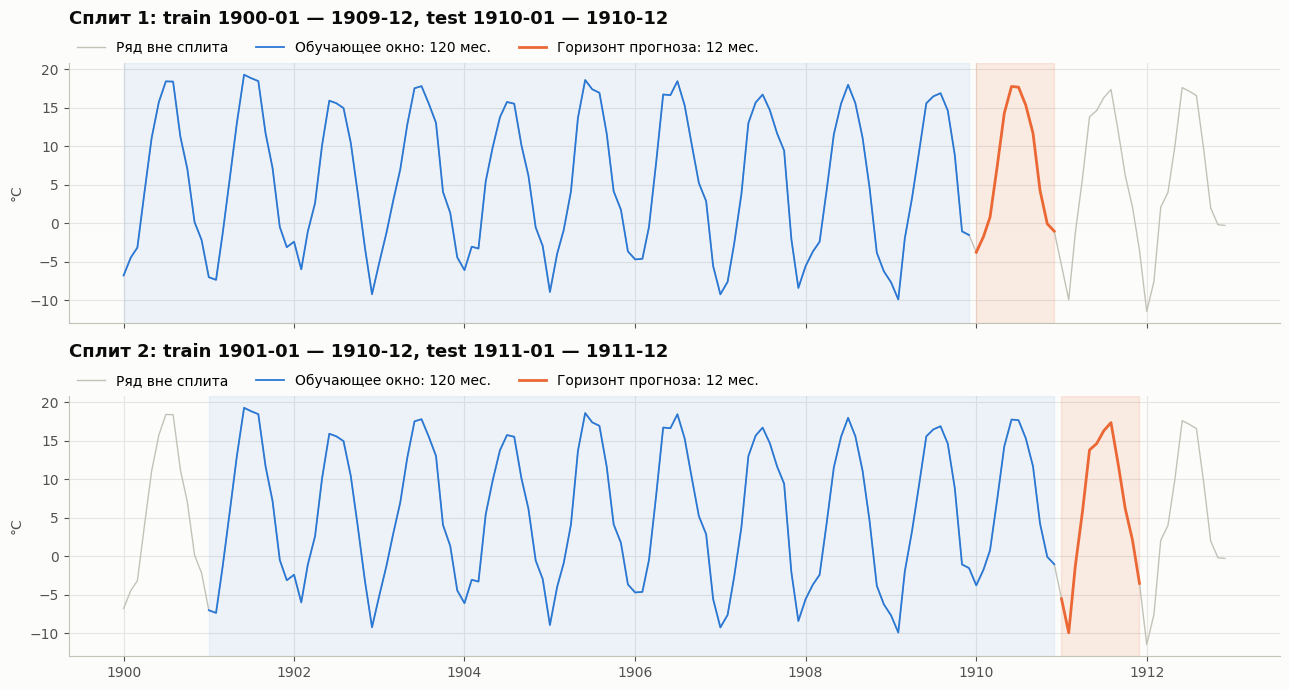

In [13]:
# Первые два сплита на самом ряду
view = ts.iloc[:TRAIN_WINDOW + 3 * HORIZON]
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
for ax, (k, (tr_idx, te_idx)) in zip(axes, enumerate(splits[:2], 1)):
    ax.plot(view.index, view, color='#c3c2b7', lw=1, label='Ряд вне сплита')
    ax.axvspan(ts.index[tr_idx[0]], ts.index[tr_idx[-1]], color=COLOR_TRAIN, alpha=0.07)
    ax.axvspan(ts.index[te_idx[0]], ts.index[te_idx[-1]], color=COLOR_TEST, alpha=0.12)
    ax.plot(ts.index[tr_idx], ts.iloc[tr_idx], color=COLOR_TRAIN, lw=1.3, label='Обучающее окно: 120 мес.')
    ax.plot(ts.index[te_idx], ts.iloc[te_idx], color=COLOR_TEST, lw=2, label='Горизонт прогноза: 12 мес.')
    ax.set_title(f'Сплит {k}: train {ts.index[tr_idx[0]]:%Y-%m} — {ts.index[tr_idx[-1]]:%Y-%m}, '
                 f'test {ts.index[te_idx[0]]:%Y-%m} — {ts.index[te_idx[-1]]:%Y-%m}')
    ax.set_ylabel('°C')
    legend_above(ax, ncol=3)
fig.tight_layout()
plt.show()

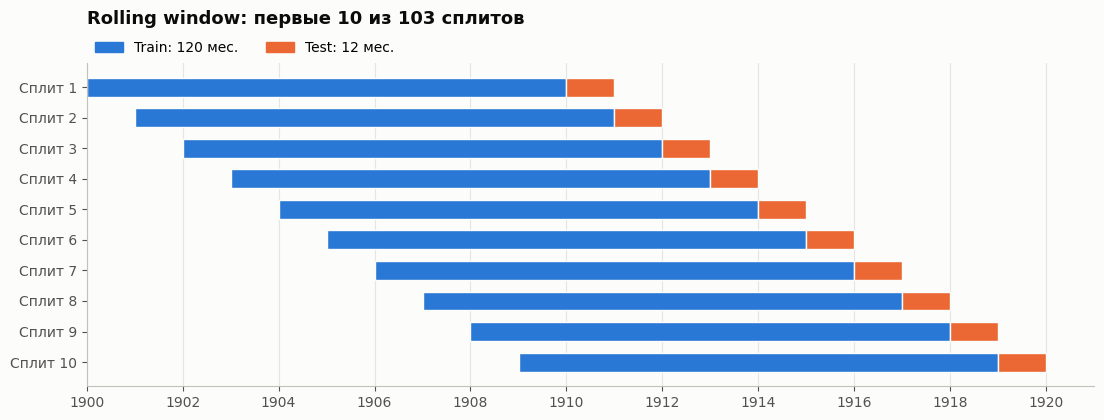

In [14]:
# Схема первых 10 сплитов: окно сдвигается на 12 месяцев
n_show = 10
fig, ax = plt.subplots(figsize=(13, 4.2))
for k, (tr_idx, te_idx) in enumerate(splits[:n_show], 1):
    for idx, color in [(tr_idx, COLOR_TRAIN), (te_idx, COLOR_TEST)]:
        left = mdates.date2num(ts.index[idx[0]])
        right = mdates.date2num(ts.index[idx[-1]] + pd.offsets.MonthBegin(1))
        ax.barh(k, right - left, left=left, height=0.62, color=color, edgecolor=COLOR_SURFACE, linewidth=1)
ax.xaxis_date()
ax.invert_yaxis()
ax.set_yticks(range(1, n_show + 1))
ax.set_yticklabels([f'Сплит {k}' for k in range(1, n_show + 1)])
ax.grid(axis='y', visible=False)
ax.set_title(f'Rolling window: первые {n_show} из {len(splits)} сплитов')
legend_above(ax, ncol=2, handles=[Patch(color=COLOR_TRAIN, label='Train: 120 мес.'),
                                  Patch(color=COLOR_TEST, label='Test: 12 мес.')])
plt.show()

**Комментарий.** На каждом шаге окно сдвигается на 12 месяцев: тестовые отрезки не пересекаются, и тест всегда строго в будущем относительно своего окна. Этот же генератор используется в разделе 7 для backtesting модели.

## 4. Генерация признаков
Обязательные признаки:
- `lag_1` — температура предыдущего месяца (инерция погоды);
- `lag_12` — температура того же месяца год назад (сезонность);
- `month` — номер месяца 1–12;
- `is_winter` — 1 для декабря, января и февраля, иначе 0.

Дополнительно: `month_sin`, `month_cos` — циклическое кодирование месяца (точка на окружности). Для линейной модели номер месяца как число неудобен: декабрь (12) и январь (1) оказываются «далеко», хотя это соседние месяцы. Эти два признака используются в улучшенной модели в п. 5.4.

Лаги строятся через `shift`, то есть только из прошлых значений: будущее в признаки не попадает. Календарные признаки зависят только от даты.

In [15]:
def calendar_features(index):
    month = index.month
    return pd.DataFrame({
        'month': month,
        'is_winter': month.isin([12, 1, 2]).astype(int),
        'month_sin': np.sin(2 * np.pi * month / 12),
        'month_cos': np.cos(2 * np.pi * month / 12),
    }, index=index)


def make_features(series):
    feats = pd.DataFrame({'temp': series, 'lag_1': series.shift(1), 'lag_12': series.shift(12)})
    return feats.join(calendar_features(series.index))


features_raw = make_features(ts)
features_raw.head(15).round(3)

,temp,lag_1,lag_12,month,is_winter,month_sin,month_cos
date,,,,,,,
1900-01-01,-6.775,NaN,NaN,1,1,0.500,0.866
1900-02-01,-4.437,-6.775,NaN,2,1,0.866,0.500
1900-03-01,-3.160,-4.437,NaN,3,0,1.000,0.000
1900-04-01,4.169,-3.160,NaN,4,0,0.866,-0.500
1900-05-01,11.077,4.169,NaN,5,0,0.500,-0.866
1900-06-01,15.757,11.077,NaN,6,0,0.000,-1.000
1900-07-01,18.446,15.757,NaN,7,0,-0.500,-0.866
1900-08-01,18.414,18.446,NaN,8,0,-0.866,-0.500
1900-09-01,11.291,18.414,NaN,9,0,-1.000,-0.000


В первых 12 строках нет `lag_12`, а в первой нет и `lag_1`: для них не хватает истории. Удаляем эти строки — это самое начало train, тестовую часть удаление не затрагивает.

In [16]:
features = features_raw.dropna().copy()
print('Строк до / после удаления NaN:', len(features_raw), '/', len(features))
print('Месяцы с is_winter = 1:', sorted(int(m) for m in features.loc[features['is_winter'] == 1, 'month'].unique()))
features.head(15).round(3)

Строк до / после удаления NaN: 1364 / 1352
Месяцы с is_winter = 1: [1, 2, 12]


,temp,lag_1,lag_12,month,is_winter,month_sin,month_cos
date,,,,,,,
1901-01-01,-7.000,-2.166,-6.775,1,1,0.500,0.866
1901-02-01,-7.349,-7.000,-4.437,2,1,0.866,0.500
1901-03-01,-1.387,-7.349,-3.160,3,0,1.000,0.000
1901-04-01,5.861,-1.387,4.169,4,0,0.866,-0.500
1901-05-01,12.999,5.861,11.077,5,0,0.500,-0.866
1901-06-01,19.309,12.999,15.757,6,0,0.000,-1.000
1901-07-01,18.865,19.309,18.446,7,0,-0.500,-0.866
1901-08-01,18.481,18.865,18.414,8,0,-0.866,-0.500
1901-09-01,11.705,18.481,11.291,9,0,-1.000,-0.000


## 5. Моделирование и прогноз
### 5.1 Train/test для модели
Используем ту же границу, что и в holdout-разбиении (раздел 2). Признаки зависят только от прошлого, поэтому для первой тестовой точки `lag_1` — это последнее значение train, которое на момент прогноза уже известно.

In [17]:
FEATURES = ['lag_1', 'lag_12', 'month', 'is_winter']                  # признаки из задания
FEATURES_CYCLIC = FEATURES + ['month_sin', 'month_cos']                 # + циклическое кодирование месяца
TARGET = 'temp'

train_feat = features.loc[features.index < test.index[0]]
test_feat = features.loc[features.index >= test.index[0]]

X_train, y_train = train_feat[FEATURES], train_feat[TARGET]
X_test, y_test = test_feat[FEATURES], test_feat[TARGET]

assert X_train.index.max() < X_test.index.min()
assert X_test.index.equals(test.index)              # тест модели - ровно holdout-тест из раздела 2
print('X_train:', X_train.shape, f'{X_train.index.min():%Y-%m} — {X_train.index.max():%Y-%m}')
print('X_test: ', X_test.shape, f'{X_test.index.min():%Y-%m} — {X_test.index.max():%Y-%m}')

X_train: (1079, 4) 1901-01 — 1990-11
X_test:  (273, 4) 1990-12 — 2013-08


In [18]:
# Проверка на утечку: для каждой тестовой точки t пересчитываем лаги ТОЛЬКО по истории до t
# и сравниваем с признаками, которые подаются в модель.
for t in X_test.index:
    past = ts.loc[:t - pd.offsets.MonthBegin(1)]     # всё, что известно строго до момента t
    assert X_test.at[t, 'lag_1'] == past.iloc[-1]
    assert X_test.at[t, 'lag_12'] == past.iloc[-12]
print(f'OK: признаки всех {len(X_test)} тестовых точек вычисляются только из прошлых значений ряда')

OK: признаки всех 273 тестовых точек вычисляются только из прошлых значений ряда


### 5.2 Обучение линейной регрессии
Модель обучается **только на train**. Масштабирование не используется (линейной регрессии оно не нужно), поэтому никакие статистики теста в обучение не попадают.

In [19]:
model = LinearRegression()
model.fit(X_train, y_train)

print('Intercept:', round(model.intercept_, 3))
pd.Series(model.coef_, index=FEATURES).round(3).rename('Коэффициент').to_frame()

Intercept: 2.767


,Коэффициент
lag_1,0.298
lag_12,0.646
month,-0.285
is_winter,-2.268


**Комментарий.** Главный вклад даёт `lag_12` (0.65): температура во многом повторяет тот же месяц прошлого года; `lag_1` (0.30) отражает инерцию погоды, а `is_winter` (−2.3 °C) дополнительно понижает прогноз зимой. Номер месяца входит в модель линейно, поэтому сезонную «волну» он описать не может — это слабое место модели, которое исправляется в п. 5.4.

### 5.3 Прогноз на тестовой выборке holdout
Прогноз на один шаг вперёд (one-step-ahead): модель обучена один раз, а для каждого месяца теста берутся лаги из уже наблюдённых значений.

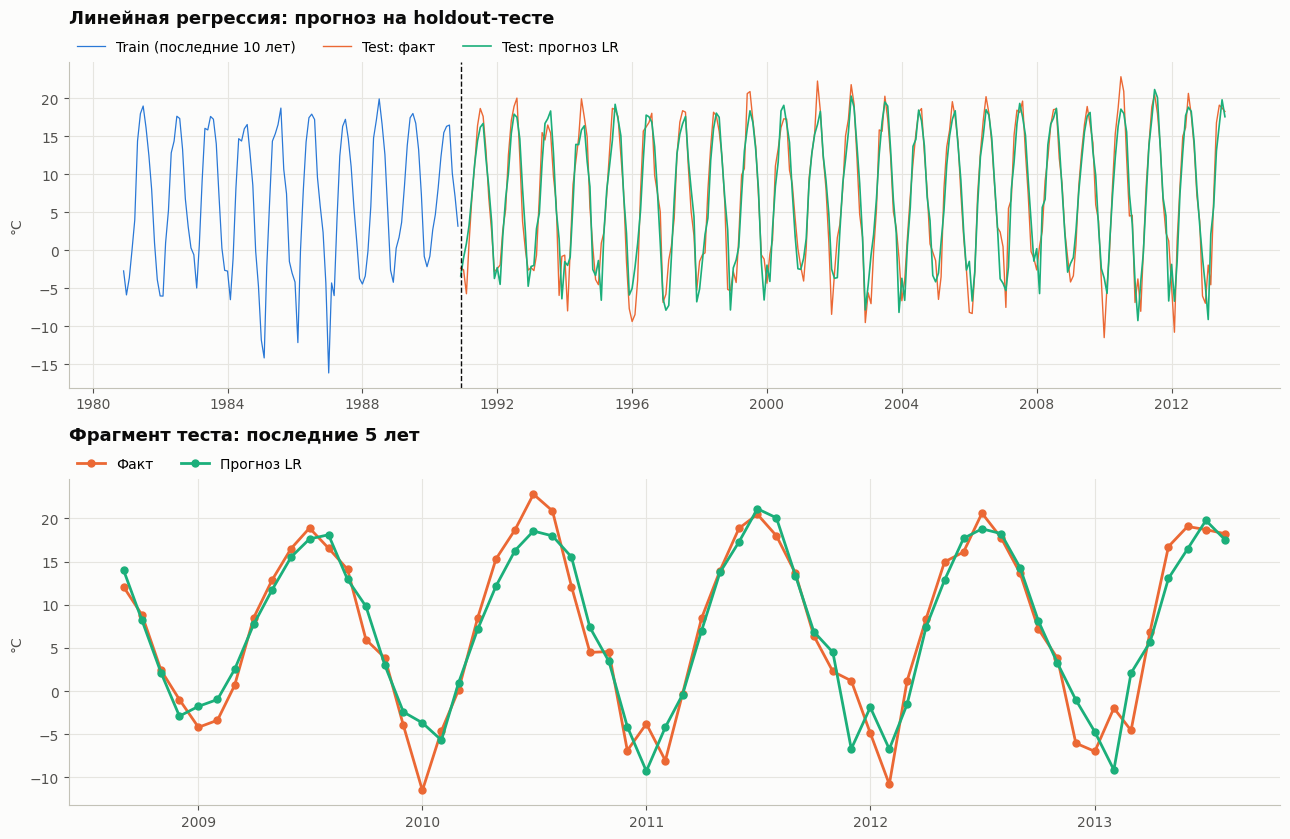

,факт,прогноз,ошибка
date,,,
1990-12-01,-2.38,-3.40,1.02
1991-01-01,-2.59,-1.02,-1.57
1991-02-01,-5.74,0.88,-6.63
1991-03-01,0.87,3.21,-2.34
1991-04-01,6.86,7.18,-0.32
1991-05-01,11.17,11.31,-0.14
1991-06-01,16.34,14.37,1.97
1991-07-01,18.63,16.16,2.48
1991-08-01,17.58,16.66,0.92


In [20]:
y_pred = pd.Series(model.predict(X_test), index=X_test.index, name='pred')

fig, axes = plt.subplots(2, 1, figsize=(13, 8.5))

ax = axes[0]
ax.plot(y_train.index[-120:], y_train.iloc[-120:], color=COLOR_TRAIN, lw=0.9, label='Train (последние 10 лет)')
ax.plot(y_test.index, y_test, color=COLOR_TEST, lw=1, label='Test: факт')
ax.plot(y_pred.index, y_pred, color=COLOR_PRED, lw=1.2, label='Test: прогноз LR')
ax.axvline(test.index[0], color=COLOR_INK, ls='--', lw=1)
ax.set_title('Линейная регрессия: прогноз на holdout-тесте')
ax.set_ylabel('°C')
legend_above(ax, ncol=3)

ax = axes[1]
last = y_test.index[-60:]
ax.plot(last, y_test.loc[last], color=COLOR_TEST, lw=2, marker='o', ms=5, label='Факт')
ax.plot(last, y_pred.loc[last], color=COLOR_PRED, lw=2, marker='o', ms=5, label='Прогноз LR')
ax.set_title('Фрагмент теста: последние 5 лет')
ax.set_ylabel('°C')
legend_above(ax, ncol=2)

fig.tight_layout()
plt.show()

pd.DataFrame({'факт': y_test, 'прогноз': y_pred, 'ошибка': y_test - y_pred}).head(12).round(2)

### 5.4 Улучшение: циклическое кодирование месяца
Та же линейная регрессия, те же признаки из задания плюс `month_sin` и `month_cos`. Обучение — на том же train, прогноз — на том же holdout-тесте.

Intercept: 2.891


,Коэффициент
lag_1,0.296
lag_12,0.072
month,0.146
is_winter,-0.379
month_sin,-2.178
month_cos,-8.030


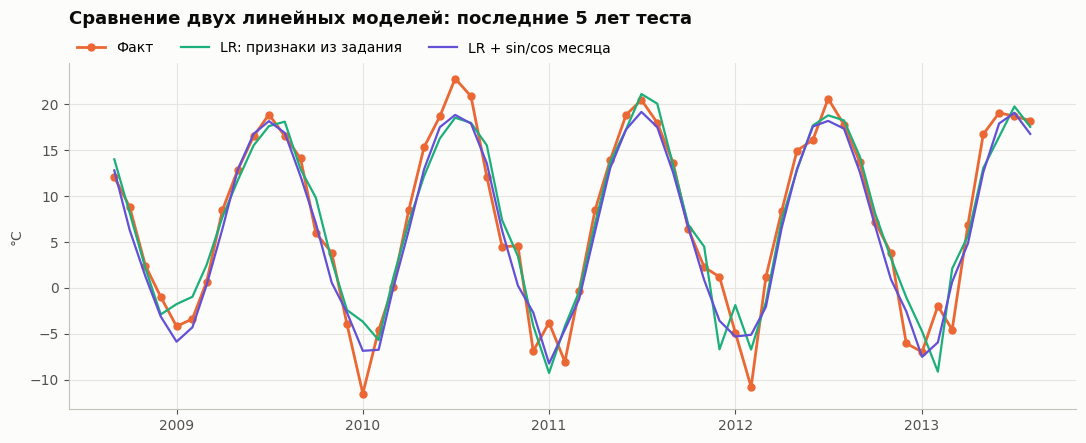

In [21]:
model_cyclic = LinearRegression()
model_cyclic.fit(train_feat[FEATURES_CYCLIC], y_train)
y_pred_cyclic = pd.Series(model_cyclic.predict(test_feat[FEATURES_CYCLIC]), index=X_test.index, name='pred_cyclic')

print('Intercept:', round(model_cyclic.intercept_, 3))
display(pd.Series(model_cyclic.coef_, index=FEATURES_CYCLIC).round(3).rename('Коэффициент').to_frame())

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(last, y_test.loc[last], color=COLOR_TEST, lw=2, marker='o', ms=5, label='Факт')
ax.plot(last, y_pred.loc[last], color=COLOR_PRED, lw=1.6, label='LR: признаки из задания')
ax.plot(last, y_pred_cyclic.loc[last], color=COLOR_PRED2, lw=1.6, label='LR + sin/cos месяца')
ax.set_title('Сравнение двух линейных моделей: последние 5 лет теста')
ax.set_ylabel('°C')
legend_above(ax, ncol=3)
plt.show()

## 6. Метрики и интерпретация
### 6.1 MAE, RMSE, MAPE

$$\text{MAE}=\frac{1}{n}\sum|y_t-\hat y_t|,\qquad \text{RMSE}=\sqrt{\frac{1}{n}\sum(y_t-\hat y_t)^2},\qquad \text{MAPE}=\frac{100\%}{n}\sum\left|\frac{y_t-\hat y_t}{y_t}\right|$$

Считаем по формулам и сверяем с реализацией `sklearn`.

In [22]:
def mae(y_true, y_hat):
    return np.mean(np.abs(y_true - y_hat))


def rmse(y_true, y_hat):
    return np.sqrt(np.mean((y_true - y_hat) ** 2))


def mape(y_true, y_hat):
    return np.mean(np.abs((y_true - y_hat) / y_true)) * 100


def evaluate(y_true, y_hat):
    y_true, y_hat = np.asarray(y_true, dtype=float), np.asarray(y_hat, dtype=float)
    return {'MAE, °C': mae(y_true, y_hat), 'RMSE, °C': rmse(y_true, y_hat), 'MAPE, %': mape(y_true, y_hat)}


predictions = {'LR: признаки из задания': y_pred, 'LR + sin/cos месяца': y_pred_cyclic}
metrics = pd.DataFrame({name: evaluate(y_test, p) for name, p in predictions.items()}).T

# Сверка собственных реализаций с sklearn
for name, p in predictions.items():
    assert np.isclose(metrics.at[name, 'MAE, °C'], mean_absolute_error(y_test, p))
    assert np.isclose(metrics.at[name, 'RMSE, °C'], np.sqrt(mean_squared_error(y_test, p)))
    assert np.isclose(metrics.at[name, 'MAPE, %'], 100 * mean_absolute_percentage_error(y_test, p))
print('Метрики совпадают с sklearn')

metrics.round(3)

Метрики совпадают с sklearn


,"MAE, °C","RMSE, °C","MAPE, %"
LR: признаки из задания,2.176,2.803,335.297
LR + sin/cos месяца,1.890,2.407,121.885


### 6.2 Сравнение с простыми бейзлайнами
Само по себе число мало о чём говорит, поэтому сравним модели с прогнозами без обучения:
- **naive**: $\hat y_t = y_{t-1}$;
- **seasonal naive**: $\hat y_t = y_{t-12}$;
- **климатическая норма**: среднее значение этого месяца по train.

Дополнительный столбец **MAPE (K)** — та же MAPE, посчитанная в Кельвинах (почему она нужна — в п. 6.3).

In [23]:
month_norm_train = y_train.groupby(y_train.index.month).mean()     # норма считается только по train

forecasts = {
    'Naive (t-1)': X_test['lag_1'],
    'Seasonal naive (t-12)': X_test['lag_12'],
    'Климатическая норма (train)': pd.Series(X_test.index.month.map(month_norm_train).values, index=X_test.index),
    **predictions,
}
comparison = pd.DataFrame({name: evaluate(y_test, f) for name, f in forecasts.items()}).T
comparison['MAPE (K), %'] = [mape(y_test.values + 273.15, np.asarray(f, dtype=float) + 273.15) for f in forecasts.values()]
comparison.round(3)

,"MAE, °C","RMSE, °C","MAPE, %","MAPE (K), %"
Naive (t-1),4.450,5.322,756.397,1.594
Seasonal naive (t-12),2.336,3.101,345.849,0.843
Климатическая норма (train),2.004,2.535,195.278,0.721
LR: признаки из задания,2.176,2.803,335.297,0.784
LR + sin/cos месяца,1.890,2.407,121.885,0.681


In [24]:
# Почему MAPE для температуры в °C ведёт себя плохо
ape = (y_test - y_pred).abs() / y_test.abs() * 100
near_zero = y_test.abs() < 1
print(f'Месяцев в тесте с |t| < 1 °C: {near_zero.sum()} из {len(y_test)}')
print(f'LR из задания: MAPE = {ape.mean():.1f}%  |  медианная APE = {ape.median():.1f}%  |  '
      f'MAPE без месяцев с |t| < 1 °C = {ape[~near_zero].mean():.1f}%')
print('\nМесяцы с наибольшей APE:')
pd.DataFrame({'факт, °C': y_test, 'прогноз, °C': y_pred, '|ошибка|, °C': (y_test - y_pred).abs(), 'APE, %': ape}) \
    .sort_values('APE, %', ascending=False).head(5).round(3)

Месяцев в тесте с |t| < 1 °C: 26 из 273
LR из задания: MAPE = 335.3%  |  медианная APE = 20.1%  |  MAPE без месяцев с |t| < 1 °C = 42.8%

Месяцы с наибольшей APE:


,"факт, °C","прогноз, °C","|ошибка|, °C","APE, %"
date,,,,
1992-11-01,0.004,2.325,2.321,58034.828
1994-03-01,0.012,-0.908,0.920,7662.930
2007-11-01,-0.202,3.711,3.913,1937.338
2000-12-01,0.193,-2.452,2.645,1370.432
2008-02-01,0.540,-5.719,6.259,1159.034


### 6.3 Почему MAPE здесь вводит в заблуждение
MAPE в °C для LR из задания — 335%, но это не значит, что прогноз «в три раза хуже факта»: у шкалы Цельсия условный ноль, а в 26 из 273 тестовых месяцев |t| < 1 °C. Один только ноябрь 1992 г. (факт 0.004 °C, ошибка всего 2.3 °C) даёт APE ≈ 58 000% и в одиночку добавляет к среднему ≈ 213 п.п.; медианная APE при этом 20%, а MAPE в Кельвинах (абсолютная шкала) — 0.7–0.8%.

Поэтому для температуры основные метрики качества — **MAE и RMSE в градусах**; MAPE в °C приводим, как требует задание, но выводы по ней не делаем.

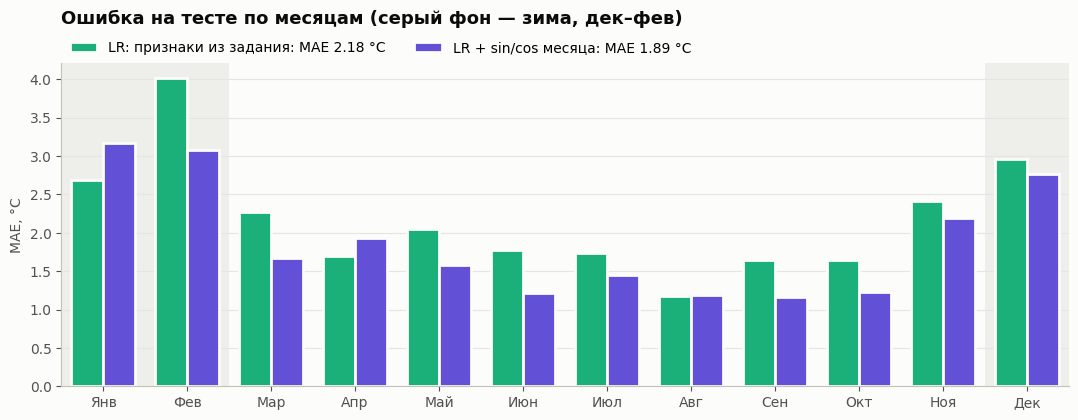

,Янв,Фев,Мар,Апр,Май,Июн,Июл,Авг,Сен,Окт,Ноя,Дек
LR: признаки из задания,2.69,4.01,2.27,1.69,2.05,1.78,1.74,1.17,1.65,1.64,2.42,2.96
LR + sin/cos месяца,3.17,3.08,1.67,1.94,1.58,1.22,1.45,1.19,1.16,1.23,2.19,2.76


In [25]:
mae_by_month = pd.DataFrame({name: (y_test - p).abs().groupby(y_test.index.month).mean()
                             for name, p in predictions.items()})

fig, ax = plt.subplots(figsize=(13, 4.2))
ax.axvspan(0.5, 2.5, color='#e6e5e0', alpha=0.6, lw=0)
ax.axvspan(11.5, 12.5, color='#e6e5e0', alpha=0.6, lw=0)
width = 0.38
for shift, name, color in zip([-width / 2, width / 2], predictions, [COLOR_PRED, COLOR_PRED2]):
    ax.bar(mae_by_month.index + shift, mae_by_month[name], width=width, color=color,
           edgecolor=COLOR_SURFACE, linewidth=2, label=f'{name}: MAE {metrics.at[name, "MAE, °C"]:.2f} °C')
ax.set_xticks(range(1, 13))
ax.set_xticklabels(MONTH_NAMES)
ax.set_xlim(0.5, 12.5)
ax.set_ylabel('MAE, °C')
ax.set_title('Ошибка на тесте по месяцам (серый фон — зима, дек–фев)')
ax.grid(axis='x', visible=False)
legend_above(ax, ncol=2)
plt.show()

mae_by_month.round(2).T.set_axis(MONTH_NAMES, axis=1)

### 6.4 Интерпретация
> **Коротко:** линейная регрессия на признаках из задания ошибается в среднем на 2.2 °C (RMSE 2.8 °C) при годовом размахе температуры ≈ 25 °C — это лучше наивных прогнозов, но чуть хуже климатической нормы. С циклическим кодированием месяца (sin/cos) та же линейная модель становится лучшей из всех: MAE 1.89 °C, RMSE 2.41 °C.

Подробнее:
- Базовая LR лучше naive (MAE 4.45 °C) и seasonal naive (2.34 °C), но уступает норме (2.00 °C): номер месяца как число не описывает сезонную кривую, и сезонность модели приходится брать из зашумлённого `lag_12`.
- `month_sin` / `month_cos` снижают MAE на 13% (2.18 → 1.89 °C) и RMSE на 14% (2.80 → 2.41 °C). Коэффициент при `lag_12` падает с 0.65 до 0.07: сезонность теперь задают гармоники, а лаги объясняют только отклонение от нормы.
- Ошибки сосредоточены зимой (MAE в январе–феврале ≈ 3 °C против 1.2–1.5 °C летом), а RMSE заметно больше MAE — есть отдельные крупные промахи в аномальные зимы. Для модели на одних лагах это естественный предел: зимние аномалии определяются атмосферной циркуляцией, которой нет среди признаков.

## 7. Дополнительно: backtesting на скользящем окне
Применяем rolling window (120 / 12) из раздела 3 **внутри train-части** — holdout-тест не трогаем. На каждом сплите заново обучаем модель на 10 годах и считаем ошибку двумя способами:
- **one-step-ahead** — как в разделе 5: `lag_1` берётся из фактических данных;
- **честный прогноз на 12 мес.** от конца окна: `lag_1` для шагов 2–12 берётся из собственного прогноза модели (рекурсивная стратегия), а `lag_12` при горизонте ≤ 12 всегда известен из истории.

Для сравнения на каждом сплите считаем и бейзлайн «климатическая норма окна» (среднее по месяцу за те же 10 лет).

In [26]:
def forecast_recursive(fitted_model, feature_list, history, future_index):
    # Многошаговый прогноз: lag_1 - из предыдущего прогноза, lag_12 - из истории (корректно при горизонте <= 12)
    hist = history.copy()
    calendar = calendar_features(future_index)
    preds = []
    for t in future_index:
        row = calendar.loc[[t]].assign(lag_1=hist.iloc[-1], lag_12=hist.iloc[-12])[feature_list]
        y_hat = fitted_model.predict(row)[0]
        preds.append(y_hat)
        hist.loc[t] = y_hat                    # дальше «история» содержит прогноз, а не факт
    return pd.Series(preds, index=future_index)


def backtest(feature_list, data, train_size=TRAIN_WINDOW, horizon=HORIZON):
    rows = []
    for k, (tr_idx, te_idx) in enumerate(rolling_window_split(len(data), train_size, horizon), 1):
        win_train, win_test = data.iloc[tr_idx], data.iloc[te_idx]
        assert win_train.index.max() < win_test.index.min()
        y_true = win_test[TARGET].values

        m = LinearRegression().fit(win_train[feature_list], win_train[TARGET])
        pred_one_step = m.predict(win_test[feature_list])
        history = ts.loc[:win_train.index[-1]]                  # всё, что известно в конце окна
        pred_12m = forecast_recursive(m, feature_list, history, win_test.index).values

        window_norm = win_train.groupby(win_train.index.month)[TARGET].mean()
        pred_norm = win_test.index.month.map(window_norm).values

        rows.append({'split': k, 'test_start': win_test.index[0],
                     'MAE one-step': mae(y_true, pred_one_step),
                     'MAE 12 мес.': mae(y_true, pred_12m),
                     'RMSE 12 мес.': rmse(y_true, pred_12m),
                     'MAE норма окна': mae(y_true, pred_norm)})
    return pd.DataFrame(rows).set_index('split')


bt = {'LR: признаки из задания': backtest(FEATURES, train_feat),
      'LR + sin/cos месяца': backtest(FEATURES_CYCLIC, train_feat)}
print('Сплитов внутри train:', len(bt['LR: признаки из задания']))

bt_summary = pd.DataFrame({name: res[['MAE one-step', 'MAE 12 мес.', 'RMSE 12 мес.']].mean() for name, res in bt.items()}).T
bt_summary.loc['Климатическая норма окна'] = [np.nan, bt['LR + sin/cos месяца']['MAE норма окна'].mean(), np.nan]
bt_summary.round(3)

Сплитов внутри train: 79


,MAE one-step,MAE 12 мес.,RMSE 12 мес.
LR: признаки из задания,2.144,2.332,2.989
LR + sin/cos месяца,1.759,1.806,2.309
Климатическая норма окна,NaN,1.799,NaN


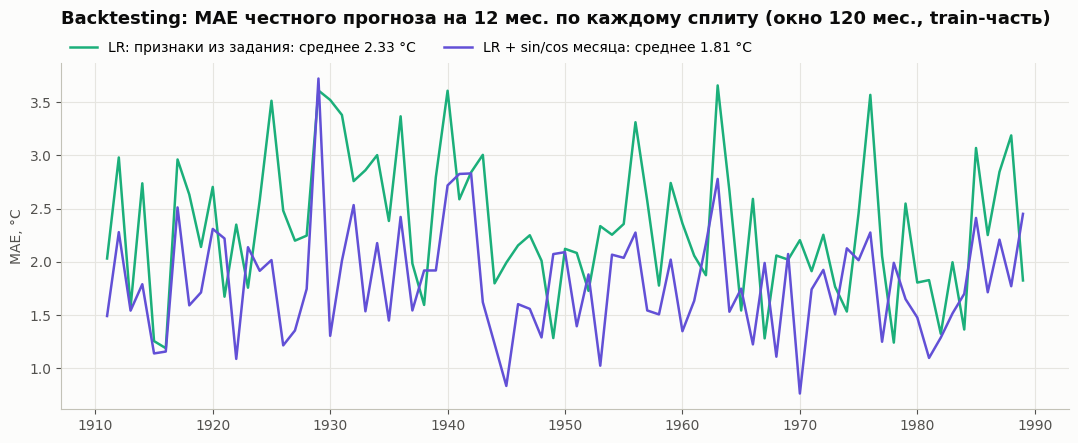

,MAE one-step,MAE 12 мес.,MAE норма окна
mean,1.759,1.806,1.799
std,0.476,0.520,0.495
min,0.797,0.762,0.729
max,3.445,3.723,3.530


In [27]:
fig, ax = plt.subplots(figsize=(13, 4.5))
for (name, res), color in zip(bt.items(), [COLOR_PRED, COLOR_PRED2]):
    ax.plot(res['test_start'], res['MAE 12 мес.'], color=color, lw=1.8,
            label=f'{name}: среднее {res["MAE 12 мес."].mean():.2f} °C')
ax.set_title('Backtesting: MAE честного прогноза на 12 мес. по каждому сплиту (окно 120 мес., train-часть)')
ax.set_ylabel('MAE, °C')
legend_above(ax, ncol=2)
plt.show()

bt['LR + sin/cos месяца'][['MAE one-step', 'MAE 12 мес.', 'MAE норма окна']].describe().loc[['mean', 'std', 'min', 'max']].round(3)

**Комментарий.** На 79 сплитах внутри train честный прогноз на 12 мес. от LR + sin/cos ошибается в среднем на 1.81 °C — на уровне климатической нормы окна (1.80 °C), а базовая LR — на 2.33 °C. One-step-ahead лишь немного точнее 12-месячного прогноза (1.76 против 1.81 °C): `lag_1` помогает только на ближайший месяц, дальше аномалии быстро затухают.

Разброс ошибки между сплитами большой (0.76–3.72 °C), поэтому одно число holdout-метрики стоит воспринимать с этой поправкой. Результат на holdout-тесте (1.89 °C) согласуется с backtesting, а преимущество sin/cos-кодирования подтверждается и внутри train — выбор модели не опирается только на тест.

## Итоги
| Этап | Результат |
|---|---|
| Данные | Belarus, 1900-01 — 2013-08: 1364 месячных наблюдения, индекс `DatetimeIndex` с частотой `MS`, пропусков нет |
| Holdout | train 1900-01 — 1990-11 (1091 мес., 80%), test 1990-12 — 2013-08 (273 мес., 20%) |
| Rolling window | 120 мес. обучения / 12 мес. прогноза, шаг 12 мес.: 103 сплита на всём ряду, корректность проверена `assert`-ами |
| Признаки | `lag_1`, `lag_12`, `month`, `is_winter` (+ `month_sin`, `month_cos`) |
| LR: признаки из задания | MAE 2.18 °C, RMSE 2.80 °C, MAPE 335% |
| LR + sin/cos месяца | MAE 1.89 °C, RMSE 2.41 °C, MAPE 122% — лучшая модель, лучше всех бейзлайнов |

**Защита от утечек:** разбиение строго по времени без перемешивания; лаги только через `shift` (проверено пересчётом по истории для каждой тестовой точки); модели и климатическая норма обучаются только на train; масштабирование не используется; backtesting выполнен внутри train, не затрагивая holdout-тест.